In [ ]:
# Check existing user roles

In [1]:

import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

roles_df = pd.read_sql_query(
    """
    SELECT
        role,
        COUNT(*) AS total_users
    FROM users
    GROUP BY role
    """,
    conn
)

display(roles_df)

print("\nExisting user accounts:")

users_df = pd.read_sql_query(
    """
    SELECT user_id, username, email, role
    FROM users
    ORDER BY user_id
    """,
    conn
)

display(users_df)

conn.close()


,role,total_users
0,admin,1
1,user,1



Existing user accounts:


,user_id,username,email,role
0,1,admin,admin@admin.com,admin
1,2,user,user@admin.com,user


In [ ]:
# Create Support Staff Account

In [3]:

import sqlite3
import bcrypt
import getpass

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

username = input("Enter support username: ").strip()
email = input("Enter support email: ").strip()
password = getpass.getpass("Enter password (minimum 12 characters): ")

if not username or not email:
    raise ValueError("Username and email are required.")

if len(password) < 12:
    raise ValueError("Password must contain at least 12 characters.")

conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

try:
    cursor.execute(
        "SELECT user_id FROM users WHERE username=? OR email=?",
        (username, email)
    )

    if cursor.fetchone():
        print("Username or email already exists.")
    else:
        password_hash = bcrypt.hashpw(
            password.encode("utf-8"),
            bcrypt.gensalt()
        ).decode("utf-8")

        cursor.execute("""
            INSERT INTO users (username, email, password_hash, role)
            VALUES (?, ?, ?, 'support')
        """, (username, email, password_hash))

        conn.commit()
        print("Support staff account created successfully.")

finally:
    conn.close()


Enter support username:  nimesh
Enter support email:  nimesh91.nimesh@gmail.com
Enter password (minimum 12 characters):  ········


Support staff account created successfully.


In [ ]:
# Check user roles

In [4]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

users_df = pd.read_sql_query("""
    SELECT user_id, username, email, role
    FROM users
    ORDER BY user_id
""", conn)

conn.close()

display(users_df)


,user_id,username,email,role
0,1,admin,admin@admin.com,admin
1,2,user,user@admin.com,user
2,3,suser,suser@email.com,support
3,4,nimesh,nimesh91.nimesh@gmail.com,support


In [ ]:
# Update Ticket Assignment

In [6]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

support_users = pd.read_sql_query("""
    SELECT user_id, username
    FROM users
    WHERE role = 'support'
    ORDER BY username
""", conn)

conn.close()

display(support_users)


,user_id,username
0,4,nimesh
1,3,suser


In [8]:

support_options = {
    row["username"]: row["user_id"]
    for _, row in support_users.iterrows()
}

print("Available Support Staff:")
print(support_options)


Available Support Staff:
{'nimesh': 4, 'suser': 3}


In [ ]:
# Check current ticket data

In [9]:

import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

ticket_metrics = pd.read_sql_query("""
    SELECT
        t.ticket_id,
        t.title,
        t.priority,
        t.status,
        creator.username AS created_by,
        support.username AS assigned_to,
        t.created_at,
        t.first_response_at,
        t.resolved_at,
        t.response_due_at,
        t.resolution_due_at
    FROM tickets t
    LEFT JOIN users creator
        ON t.user_id = creator.user_id
    LEFT JOIN users support
        ON t.assigned_to = support.user_id
    ORDER BY t.ticket_id DESC
""", conn)

conn.close()

display(ticket_metrics)


,ticket_id,title,priority,status,created_by,assigned_to,created_at,first_response_at,resolved_at,response_due_at,resolution_due_at
0,5,printer not working,Medium,Open,nimesh,nimesh,2026-11-03 05:28:44,None,None,2026-11-03 09:34:16,2026-11-04 05:34:16
1,4,scanner not working,Medium,In Progress,admin,nimesh,2026-11-02 10:15:57,None,None,2026-11-03 09:38:03,2026-11-04 05:38:03
2,3,my account not working,High,Open,user,NaN,2026-11-02 10:14:56,None,None,2026-11-02 11:14:56,2026-11-02 18:14:56
3,2,printer not working,Low,Open,NaN,NaN,2026-11-02 09:22:50,None,None,2026-11-02 17:22:50,2026-11-05 09:22:50
4,1,Printer is offline,Medium,Open,NaN,NaN,2026-11-02 09:12:43,None,None,2026-11-02 13:12:43,2026-11-03 09:12:43


In [ ]:
# KPI Calculation

In [12]:
import sqlite3
import pandas as pd
from datetime import datetime

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

df = pd.read_sql_query("""
    SELECT
        ticket_id,
        title,
        priority,
        status,
        created_at,
        first_response_at,
        resolved_at,
        response_due_at,
        resolution_due_at
    FROM tickets
""", conn)

conn.close()

# Convert timestamps to datetime
date_columns = [
    "created_at",
    "first_response_at",
    "resolved_at",
    "response_due_at",
    "resolution_due_at"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Calculate response and resolution times in hours
df["FRT_Hours"] = (
    df["first_response_at"] - df["created_at"]
).dt.total_seconds() / 3600

df["Resolution_Hours"] = (
    df["resolved_at"] - df["created_at"]
).dt.total_seconds() / 3600

# Current UTC time (database timestamps are treated as UTC)
now = pd.Timestamp.now(tz="UTC").tz_localize(None)

# SLA evaluation
df["Response_SLA"] = "Pending"
df["Resolution_SLA"] = "Pending"

response_recorded = df["first_response_at"].notna()
response_valid = response_recorded & df["response_due_at"].notna()

df.loc[response_valid, "Response_SLA"] = (
    df.loc[response_valid, "first_response_at"]
    <= df.loc[response_valid, "response_due_at"]
).map({True: "Met", False: "Breached"})

response_overdue = (
    df["first_response_at"].isna()
    & df["response_due_at"].notna()
    & (df["response_due_at"] < now)
)
df.loc[response_overdue, "Response_SLA"] = "Overdue"

resolved = df["resolved_at"].notna()
resolution_valid = resolved & df["resolution_due_at"].notna()

df.loc[resolution_valid, "Resolution_SLA"] = (
    df.loc[resolution_valid, "resolved_at"]
    <= df.loc[resolution_valid, "resolution_due_at"]
).map({True: "Met", False: "Breached"})

resolution_overdue = (
    df["resolved_at"].isna()
    & df["resolution_due_at"].notna()
    & (df["resolution_due_at"] < now)
)
df.loc[resolution_overdue, "Resolution_SLA"] = "Overdue"

# KPI summary
avg_frt = df["FRT_Hours"].mean()
avg_resolution = df["Resolution_Hours"].mean()

response_evaluated = df["Response_SLA"].isin(["Met", "Breached"])
resolution_evaluated = df["Resolution_SLA"].isin(["Met", "Breached"])

response_compliance = (
    (df.loc[response_evaluated, "Response_SLA"] == "Met").mean() * 100
    if response_evaluated.any() else None
)

resolution_compliance = (
    (df.loc[resolution_evaluated, "Resolution_SLA"] == "Met").mean() * 100
    if resolution_evaluated.any() else None
)

print("===== IT SUPPORT PERFORMANCE KPIs =====")
print("Total Tickets:", len(df))
print("Average First Response Time:",
      f"{avg_frt:.2f} hours" if pd.notna(avg_frt) else "Not available")
print("Average Resolution Time:",
      f"{avg_resolution:.2f} hours" if pd.notna(avg_resolution) else "Not available")
print("Response SLA Compliance:",
      f"{response_compliance:.2f}%" if response_compliance is not None else "Not available")
print("Resolution SLA Compliance:",
      f"{resolution_compliance:.2f}%" if resolution_compliance is not None else "Not available")

display(df[[
    "ticket_id",
    "title",
    "status",
    "FRT_Hours",
    "Resolution_Hours",
    "Response_SLA",
    "Resolution_SLA"
]])


===== IT SUPPORT PERFORMANCE KPIs =====
Total Tickets: 5
Average First Response Time: Not available
Average Resolution Time: Not available
Response SLA Compliance: Not available
Resolution SLA Compliance: Not available


,ticket_id,title,status,FRT_Hours,Resolution_Hours,Response_SLA,Resolution_SLA
0,1,Printer is offline,Open,NaN,NaN,Overdue,Pending
1,2,printer not working,Open,NaN,NaN,Overdue,Pending
2,3,my account not working,Open,NaN,NaN,Overdue,Overdue
3,4,scanner not working,In Progress,NaN,NaN,Pending,Pending
4,5,printer not working,Open,NaN,NaN,Pending,Pending


In [ ]:
#Support Staff Performance

In [11]:

import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

staff_performance = pd.read_sql_query("""
    SELECT
        u.username AS support_staff,
        COUNT(t.ticket_id) AS assigned_tickets,
        SUM(CASE WHEN t.status = 'Open' THEN 1 ELSE 0 END) AS open_tickets,
        SUM(CASE WHEN t.status = 'In Progress' THEN 1 ELSE 0 END) AS in_progress,
        SUM(CASE WHEN t.status = 'Resolved' THEN 1 ELSE 0 END) AS resolved
    FROM users u
    LEFT JOIN tickets t
        ON u.user_id = t.assigned_to
    WHERE u.role = 'support'
    GROUP BY u.user_id, u.username
    ORDER BY assigned_tickets DESC
""", conn)

conn.close()

display(staff_performance)


,support_staff,assigned_tickets,open_tickets,in_progress,resolved
0,nimesh,2,1,1,0
1,suser,0,0,0,0


In [ ]:
# Load Analytics Data

In [13]:
import sqlite3
import pandas as pd
import numpy as np

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

analytics_df = pd.read_sql_query("""
    SELECT
        t.ticket_id,
        t.title,
        t.priority,
        t.status,
        t.created_at,
        t.first_response_at,
        t.resolved_at,
        t.response_due_at,
        t.resolution_due_at,
        u.username AS support_staff,
        c.category_name
    FROM tickets t
    LEFT JOIN users u
        ON t.assigned_to = u.user_id
    LEFT JOIN categories c
        ON t.category_id = c.category_id
    ORDER BY t.created_at
""", conn)

conn.close()

date_columns = [
    "created_at",
    "first_response_at",
    "resolved_at",
    "response_due_at",
    "resolution_due_at"
]

for col in date_columns:
    analytics_df[col] = pd.to_datetime(
        analytics_df[col], errors="coerce"
    )

# Calculate response time and resolution time in hours
analytics_df["FRT_Hours"] = (
    analytics_df["first_response_at"]
    - analytics_df["created_at"]
).dt.total_seconds() / 3600

analytics_df["Resolution_Hours"] = (
    analytics_df["resolved_at"]
    - analytics_df["created_at"]
).dt.total_seconds() / 3600

# Calculate SLA results only for completed events
response_evaluated = (
    analytics_df["first_response_at"].notna()
    & analytics_df["response_due_at"].notna()
)

resolution_evaluated = (
    analytics_df["resolved_at"].notna()
    & analytics_df["resolution_due_at"].notna()
)

analytics_df["Response_SLA"] = "Pending"
analytics_df["Resolution_SLA"] = "Pending"

analytics_df.loc[response_evaluated, "Response_SLA"] = np.where(
    analytics_df.loc[response_evaluated, "first_response_at"]
    <= analytics_df.loc[response_evaluated, "response_due_at"],
    "Met",
    "Breached"
)

analytics_df.loc[resolution_evaluated, "Resolution_SLA"] = np.where(
    analytics_df.loc[resolution_evaluated, "resolved_at"]
    <= analytics_df.loc[resolution_evaluated, "resolution_due_at"],
    "Met",
    "Breached"
)

print("Analytics records loaded:", len(analytics_df))
display(analytics_df.head())


Analytics records loaded: 5


,ticket_id,title,priority,status,created_at,first_response_at,resolved_at,response_due_at,resolution_due_at,support_staff,category_name,FRT_Hours,Resolution_Hours,Response_SLA,Resolution_SLA
0,1,Printer is offline,Medium,Open,2026-11-02 09:12:43,NaT,NaT,2026-11-02 13:12:43,2026-11-03 09:12:43,NaN,Printer,NaN,NaN,Pending,Pending
1,2,printer not working,Low,Open,2026-11-02 09:22:50,NaT,NaT,2026-11-02 17:22:50,2026-11-05 09:22:50,NaN,Printer,NaN,NaN,Pending,Pending
2,3,my account not working,High,Open,2026-11-02 10:14:56,NaT,NaT,2026-11-02 11:14:56,2026-11-02 18:14:56,NaN,Account & Password,NaN,NaN,Pending,Pending
3,4,scanner not working,Medium,In Progress,2026-11-02 10:15:57,NaT,NaT,2026-11-03 09:38:03,2026-11-04 05:38:03,nimesh,Software,NaN,NaN,Pending,Pending
4,5,printer not working,Medium,Resolved,2026-11-03 05:28:44,NaT,2026-11-03 06:19:04,2026-11-03 09:34:16,2026-11-04 05:34:16,nimesh,Printer,NaN,0.838889,Pending,Met


In [ ]:
#Support Staff Performance Comparison

In [14]:

staff_df = analytics_df.dropna(subset=["support_staff"]).copy()

staff_performance = (
    staff_df.groupby("support_staff")
    .agg(
        Assigned_Tickets=("ticket_id", "count"),
        Resolved_Tickets=("status", lambda x: (x == "Resolved").sum()),
        Open_Tickets=("status", lambda x: (x == "Open").sum()),
        In_Progress=("status", lambda x: (x == "In Progress").sum()),
        Average_FRT_Hours=("FRT_Hours", "mean"),
        Average_Resolution_Hours=("Resolution_Hours", "mean"),
        Response_SLA_Evaluated=("Response_SLA",
            lambda x: x.isin(["Met", "Breached"]).sum()),
        Response_SLA_Met=("Response_SLA",
            lambda x: (x == "Met").sum()),
        Resolution_SLA_Evaluated=("Resolution_SLA",
            lambda x: x.isin(["Met", "Breached"]).sum()),
        Resolution_SLA_Met=("Resolution_SLA",
            lambda x: (x == "Met").sum())
    )
    .reset_index()
)

staff_performance["Response_SLA_Compliance_%"] = (
    staff_performance["Response_SLA_Met"]
    / staff_performance["Response_SLA_Evaluated"].replace(0, np.nan)
    * 100
)

staff_performance["Resolution_SLA_Compliance_%"] = (
    staff_performance["Resolution_SLA_Met"]
    / staff_performance["Resolution_SLA_Evaluated"].replace(0, np.nan)
    * 100
)

display(staff_performance.round(2))


,support_staff,Assigned_Tickets,Resolved_Tickets,Open_Tickets,In_Progress,Average_FRT_Hours,Average_Resolution_Hours,Response_SLA_Evaluated,Response_SLA_Met,Resolution_SLA_Evaluated,Resolution_SLA_Met,Response_SLA_Compliance_%,Resolution_SLA_Compliance_%
0,nimesh,2,1,0,1,NaN,0.84,0,0,1,1,NaN,100.0


In [ ]:
# Daily Ticket Trend

,Date,Total_Tickets,Resolved
0,2026-11-02,4,0
1,2026-11-03,1,1


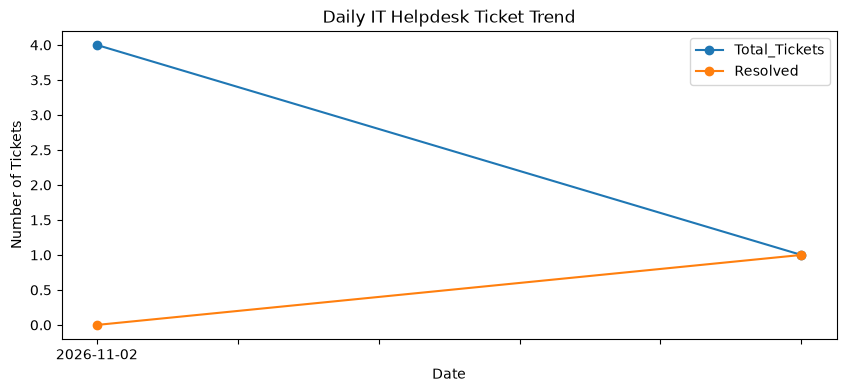

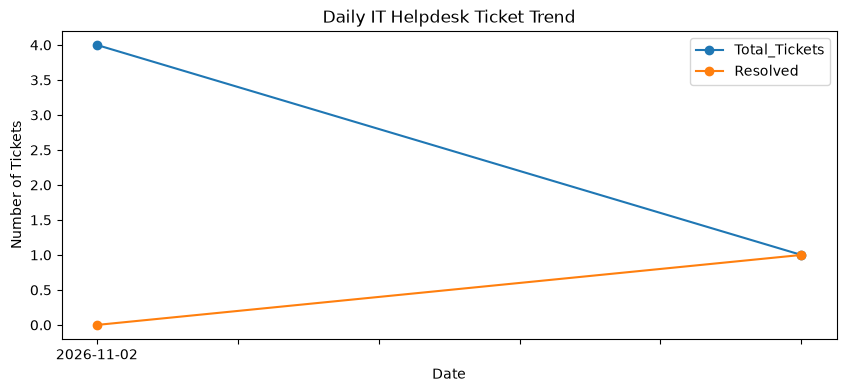

In [15]:

daily_trend = (
    analytics_df.dropna(subset=["created_at"])
    .assign(Date=lambda x: x["created_at"].dt.date)
    .groupby("Date")
    .agg(
        Total_Tickets=("ticket_id", "count"),
        Resolved=("status", lambda x: (x == "Resolved").sum())
    )
    .reset_index()
)

display(daily_trend)

if not daily_trend.empty:
    daily_chart = daily_trend.set_index("Date")
    daily_chart.index = daily_chart.index.astype(str)
    display(daily_chart.plot(
        kind="line",
        marker="o",
        title="Daily IT Helpdesk Ticket Trend",
        ylabel="Number of Tickets",
        xlabel="Date",
        figsize=(10, 4)
    ).get_figure())


In [ ]:
# Monthly Ticket Trend

In [16]:
monthly_trend = (
    analytics_df.dropna(subset=["created_at"])
    .assign(Month=lambda x: x["created_at"].dt.to_period("M").astype(str))
    .groupby("Month")
    .agg(
        Total_Tickets=("ticket_id", "count"),
        Resolved=("status", lambda x: (x == "Resolved").sum()),
        Open=("status", lambda x: (x == "Open").sum())
    )
    .reset_index()
)

display(monthly_trend)

,Month,Total_Tickets,Resolved,Open
0,2026-11,5,1,3


In [ ]:
# Priority-wise Ticket Analysis

In [17]:
priority_analysis = (
    analytics_df.groupby("priority", dropna=False)
    .agg(
        Total_Tickets=("ticket_id", "count"),
        Resolved=("status", lambda x: (x == "Resolved").sum()),
        Open=("status", lambda x: (x == "Open").sum()),
        In_Progress=("status", lambda x: (x == "In Progress").sum())
    )
    .reset_index()
)

display(priority_analysis)

,priority,Total_Tickets,Resolved,Open,In_Progress
0,High,1,0,1,0
1,Low,1,0,1,0
2,Medium,3,1,1,1


In [18]:
display(staff_performance.round(2))
display(daily_trend)
display(monthly_trend)
display(priority_analysis)

,support_staff,Assigned_Tickets,Resolved_Tickets,Open_Tickets,In_Progress,Average_FRT_Hours,Average_Resolution_Hours,Response_SLA_Evaluated,Response_SLA_Met,Resolution_SLA_Evaluated,Resolution_SLA_Met,Response_SLA_Compliance_%,Resolution_SLA_Compliance_%
0,nimesh,2,1,0,1,NaN,0.84,0,0,1,1,NaN,100.0


,Date,Total_Tickets,Resolved
0,2026-11-02,4,0
1,2026-11-03,1,1


,Month,Total_Tickets,Resolved,Open
0,2026-11,5,1,3


,priority,Total_Tickets,Resolved,Open,In_Progress
0,High,1,0,1,0
1,Low,1,0,1,0
2,Medium,3,1,1,1
